Gnerating 40 image pairs

In [36]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from pathlib import Path
from itertools import combinations

# Project root
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Exact paths based on your VS Code Explorer
DATASET_ROOT = PROJECT_ROOT / "dataset"
DATASET_PATH = DATASET_ROOT / "lfw-deepfunneled"

LANDMARKER_PATH = PROJECT_ROOT / "models" / "face_landmarker.task"
SFACE_PATH = PROJECT_ROOT / "models" / "face_recognition_sface.onnx"

# Verify paths
assert DATASET_ROOT.is_dir(), f"Dataset folder missing: {DATASET_ROOT}"
assert DATASET_PATH.is_dir(), f"LFW folder missing: {DATASET_PATH}"
assert LANDMARKER_PATH.is_file(), f"MediaPipe model missing: {LANDMARKER_PATH}"
assert SFACE_PATH.is_file(), f"SFace model missing: {SFACE_PATH}"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("MediaPipe model found:", LANDMARKER_PATH.exists())
print("SFace model found:", SFACE_PATH.exists())

# Load MediaPipe with support for multiple faces

base_options = mp.tasks.BaseOptions(
    model_asset_path=str(LANDMARKER_PATH)
)

options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=5,
    min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5
)

landmarker = mp.tasks.vision.FaceLandmarker.create_from_options(options)

print("MediaPipe initialized for up to 5 faces.")


# Check dataset images
lfw_images = list(DATASET_PATH.rglob("*.jpg"))

print("\nTotal LFW images found:", len(lfw_images))
print("Models initialized successfully.")


Project root: D:\Identity_Monitoring
Dataset path: D:\Identity_Monitoring\dataset\lfw-deepfunneled
MediaPipe model found: True
SFace model found: True
MediaPipe initialized for up to 5 faces.

Total LFW images found: 13233
Models initialized successfully.


Total identities found: 5749
Identities with 2+ images: 1680

Pair generation completed!
Genuine pairs: 20
Impostor pairs: 20
Total pairs: 40


,pair_type,reference_identity,probe_identity,expected
0,Impostor,Wen_Jiabao,Joe_Friedberg,MISMATCH
1,Impostor,Thomas_Daily,Zulfiqar_Ahmed,MISMATCH
2,Impostor,Antonio_Cassano,Michael_Haneke,MISMATCH
3,Impostor,Gabriel_Farhi,Gideon_Yago,MISMATCH
4,Impostor,Matt_Roney,Roy_Romanow,MISMATCH
5,Genuine,George_W_Bush,George_W_Bush,MATCH
6,Genuine,George_W_Bush,George_W_Bush,MATCH
7,Genuine,Bill_Simon,Bill_Simon,MATCH
8,Impostor,Kelly_Clarkson,Juergen_Peters,MISMATCH
9,Impostor,Jack_Valenti,David_Zeplowitz,MISMATCH


Pair 1 | Genuine | Expected: MATCH
Pair 2 | Genuine | Expected: MATCH
Pair 3 | Genuine | Expected: MATCH
Pair 4 | Genuine | Expected: MATCH
Pair 5 | Genuine | Expected: MATCH
Pair 6 | Impostor | Expected: MISMATCH
Pair 7 | Impostor | Expected: MISMATCH
Pair 8 | Impostor | Expected: MISMATCH
Pair 9 | Impostor | Expected: MISMATCH
Pair 10 | Impostor | Expected: MISMATCH


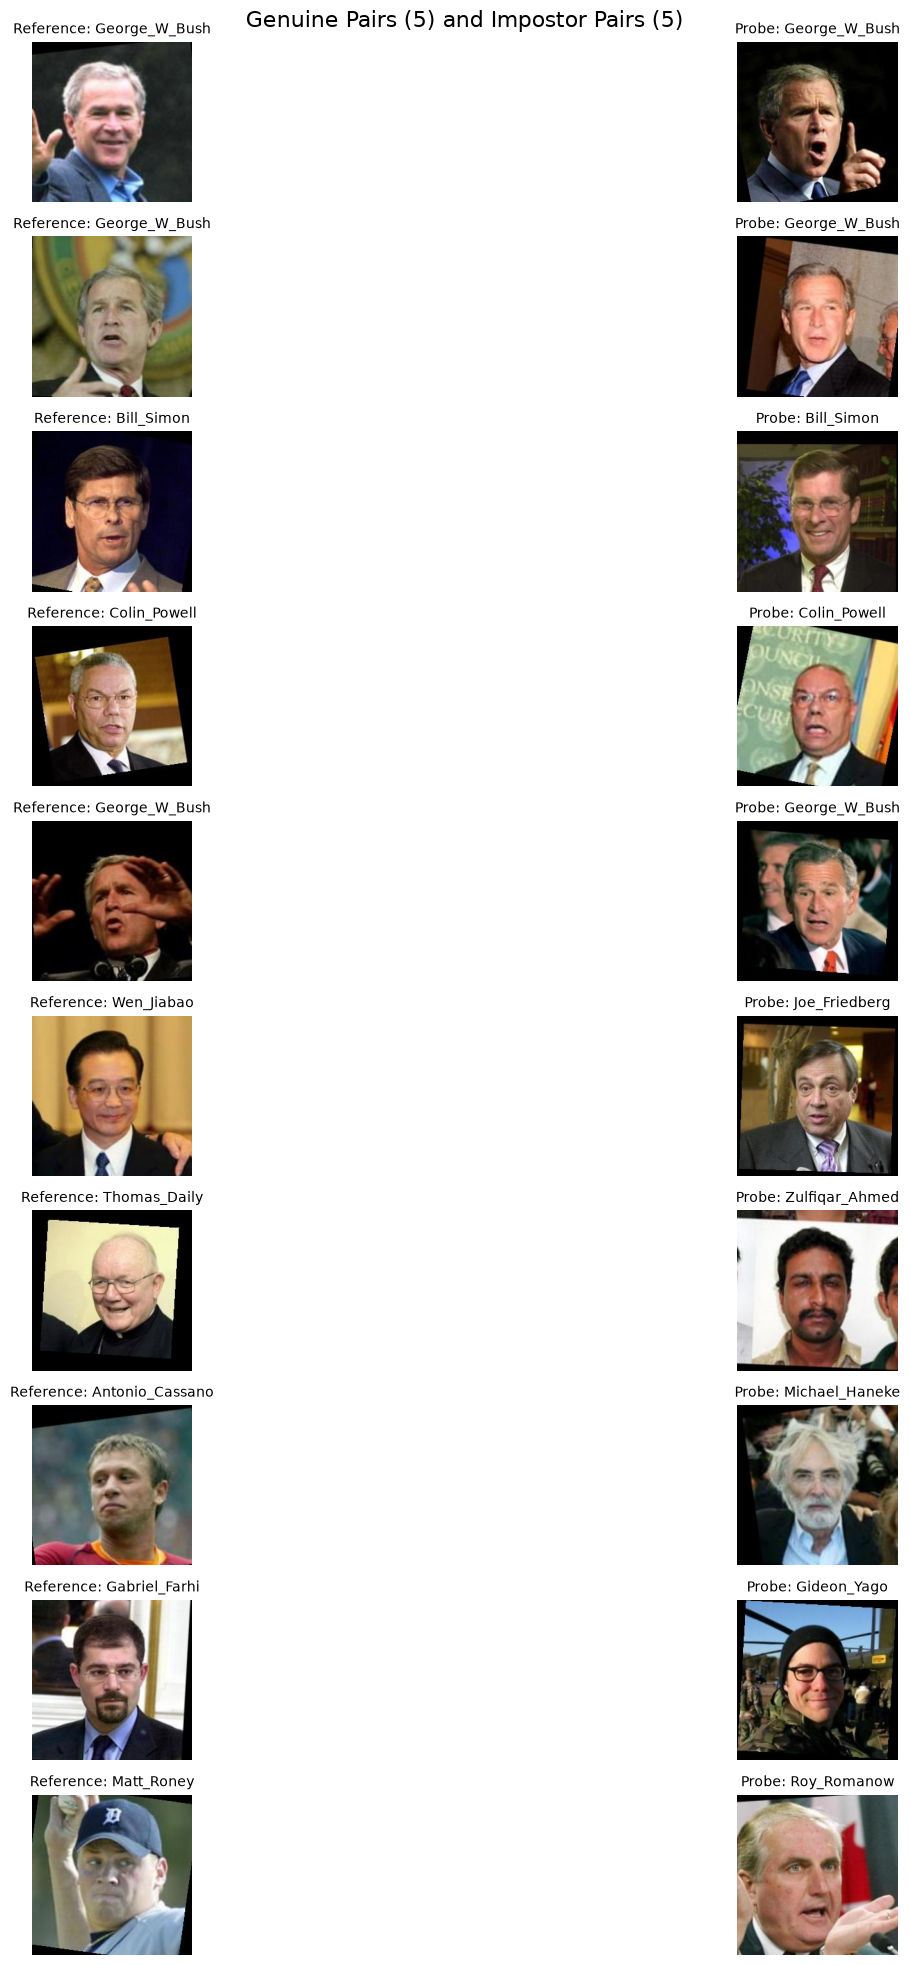

In [37]:
import random
import pandas as pd
from itertools import combinations

# Reproducible random selection
random.seed(42)

# 1. Group images by identity folder
identity_images = {}

for image_path in DATASET_PATH.rglob("*.jpg"):
    identity = image_path.parent.name
    identity_images.setdefault(identity, []).append(image_path)

# Keep identities having at least two images
eligible_identities = {
    identity: images
    for identity, images in identity_images.items()
    if len(images) >= 2
}

print("Total identities found:", len(identity_images))
print("Identities with 2+ images:", len(eligible_identities))

# 2. Generate 20 genuine pairs
genuine_pairs = []

for identity, images in eligible_identities.items():
    for img1, img2 in combinations(images, 2):
        genuine_pairs.append({
            "pair_type": "Genuine",
            "reference_identity": identity,
            "probe_identity": identity,
            "reference_path": img1,
            "probe_path": img2,
            "expected": "MATCH"
        })

if len(genuine_pairs) < 20:
    raise ValueError("Not enough genuine pairs in the dataset.")

genuine_pairs = random.sample(genuine_pairs, 20)

# 3. Generate 20 impostor pairs
identity_names = list(identity_images.keys())

impostor_pairs = []
used_pairs = set()

while len(impostor_pairs) < 20:

    id1, id2 = random.sample(identity_names, 2)

    img1 = random.choice(identity_images[id1])
    img2 = random.choice(identity_images[id2])

    pair_key = tuple(sorted([str(img1), str(img2)]))

    if pair_key in used_pairs:
        continue

    used_pairs.add(pair_key)

    impostor_pairs.append({
        "pair_type": "Impostor",
        "reference_identity": id1,
        "probe_identity": id2,
        "reference_path": img1,
        "probe_path": img2,
        "expected": "MISMATCH"
    })

# 4. Combine both pair types
test_pairs = genuine_pairs + impostor_pairs

random.shuffle(test_pairs)

pairs_df = pd.DataFrame(test_pairs)

print("\nPair generation completed!")
print("Genuine pairs:", len(genuine_pairs))
print("Impostor pairs:", len(impostor_pairs))
print("Total pairs:", len(pairs_df))

display(
    pairs_df[
        ["pair_type", "reference_identity",
         "probe_identity", "expected"]
    ].head(10)
)



# Select 5 genuine pairs and 5 impostor pairs
genuine_samples = pairs_df[
    pairs_df["pair_type"] == "Genuine"
].head(5)

impostor_samples = pairs_df[
    pairs_df["pair_type"] == "Impostor"
].head(5)

# Combine samples
sample_pairs = pd.concat(
    [genuine_samples, impostor_samples],
    ignore_index=True
)

# Display 10 pairs (20 images)
fig, axes = plt.subplots(10, 2, figsize=(20, 20))

for i, (_, pair) in enumerate(sample_pairs.iterrows()):

    # Load reference image
    reference_img = cv2.imread(str(pair["reference_path"]))
    reference_img = cv2.cvtColor(reference_img, cv2.COLOR_BGR2RGB)

    # Load probe image
    probe_img = cv2.imread(str(pair["probe_path"]))
    probe_img = cv2.cvtColor(probe_img, cv2.COLOR_BGR2RGB)

    # Display reference
    axes[i, 0].imshow(reference_img)
    axes[i, 0].set_title(
        f'Reference: {pair["reference_identity"]}',
        fontsize=10
    )
    axes[i, 0].axis("off")

    # Display probe
    axes[i, 1].imshow(probe_img)
    axes[i, 1].set_title(
        f'Probe: {pair["probe_identity"]}',
        fontsize=10
    )
    axes[i, 1].axis("off")

    print(
        f'Pair {i+1} | {pair["pair_type"]} | '
        f'Expected: {pair["expected"]}'
    )

plt.suptitle(
    "Genuine Pairs (5) and Impostor Pairs (5)",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [38]:
def extract_face_embedding(image_path):

    # 1. Load image
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unable to load image: {image_path}")

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 2. Detect face using MediaPipe
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    result = landmarker.detect(mp_image)


    # Check whether any face was detected
    if len(result.face_landmarks) == 0:
        raise ValueError("No face detected.")

    # Select the largest detected face
    # This is an LFW evaluation policy, not webcam monitoring logic

    def calculate_face_area(face_landmarks):
        xs = [point.x for point in face_landmarks]
        ys = [point.y for point in face_landmarks]

        return (
            (max(xs) - min(xs)) *
            (max(ys) - min(ys))
        )

    landmarks = max(
        result.face_landmarks,
        key=calculate_face_area
    )
    

    height, width, _ = image.shape

    # 3. Calculate face bounding box
    x_coords = [int(point.x * width) for point in landmarks]
    y_coords = [int(point.y * height) for point in landmarks]

    x_min = max(0, min(x_coords))
    y_min = max(0, min(y_coords))
    x_max = min(width - 1, max(x_coords))
    y_max = min(height - 1, max(y_coords))

    # 4. Extract five facial reference points
    def get_point(index):
        return np.array([
            landmarks[index].x * width,
            landmarks[index].y * height
        ], dtype=np.float32)

    right_eye = (get_point(33) + get_point(133)) / 2
    left_eye = (get_point(263) + get_point(362)) / 2
    nose = get_point(1)
    right_mouth = get_point(61)
    left_mouth = get_point(291)

    five_points = np.array([
        right_eye,
        left_eye,
        nose,
        right_mouth,
        left_mouth
    ], dtype=np.float32)

    # 5. Prepare SFace face data
    face_data = np.array([
        x_min,
        y_min,
        x_max - x_min,
        y_max - y_min,
        *five_points.flatten(),
        1.0
    ], dtype=np.float32)

    # 6. Align face
    aligned_face = recognizer.alignCrop(
        image,
        face_data.reshape(1, -1)
    )

    # 7. Extract embedding
    embedding = recognizer.feature(aligned_face).flatten()

    # 8. Normalize embedding
    norm = np.linalg.norm(embedding)

    if norm == 0:
        raise ValueError("Invalid zero embedding.")

    return embedding / norm


print("Face embedding function defined successfully.")


Face embedding function defined successfully.


Extract embeddings for all unique images

In [39]:
# Cache embeddings for unique images
embedding_cache = {}

all_image_paths = set(
    pairs_df["reference_path"].tolist()
    + pairs_df["probe_path"].tolist()
)

print("Total unique images to process:", len(all_image_paths))

successful_images = 0
failed_images = []

for image_path in all_image_paths:

    try:
        embedding = extract_face_embedding(image_path)

        embedding_cache[image_path] = embedding
        successful_images += 1

    except Exception as error:
        failed_images.append({
            "image": str(image_path),
            "error": str(error)
        })

print("\nEmbedding extraction completed!")
print("Successful images:", successful_images)
print("Failed images:", len(failed_images))
print("Cached embeddings:", len(embedding_cache))

if failed_images:
    print("\nFailed image details:")
    display(pd.DataFrame(failed_images).head())


Total unique images to process: 79

Embedding extraction completed!
Successful images: 79
Failed images: 0
Cached embeddings: 79


COMPARING ALL 40 IMAGE PAIRS 

Calculate similarity and verify identities

In [40]:
THRESHOLD = 0.3822

results = []

for _, pair in pairs_df.iterrows():

    reference_path = pair["reference_path"]
    probe_path = pair["probe_path"]

    reference_embedding = embedding_cache[reference_path]
    probe_embedding = embedding_cache[probe_path]

    # Calculate cosine similarity
    similarity = float(
        np.dot(reference_embedding, probe_embedding)
    )

    # Predict identity
    predicted = (
        "MATCH" if similarity >= THRESHOLD
        else "MISMATCH"
    )

    results.append({
        "pair_type": pair["pair_type"],
        "reference_identity": pair["reference_identity"],
        "probe_identity": pair["probe_identity"],
        "expected": pair["expected"],
        "similarity": similarity,
        "predicted": predicted,
        "status": (
            "Correct" if predicted == pair["expected"]
            else "Incorrect"
        )
    })

results_df = pd.DataFrame(results)

print("Total pairs compared:", len(results_df))
display(results_df)


Total pairs compared: 40


,pair_type,reference_identity,probe_identity,expected,similarity,predicted,status
0,Impostor,Wen_Jiabao,Joe_Friedberg,MISMATCH,-0.038116,MISMATCH,Correct
1,Impostor,Thomas_Daily,Zulfiqar_Ahmed,MISMATCH,-0.061901,MISMATCH,Correct
2,Impostor,Antonio_Cassano,Michael_Haneke,MISMATCH,0.124155,MISMATCH,Correct
3,Impostor,Gabriel_Farhi,Gideon_Yago,MISMATCH,0.093058,MISMATCH,Correct
4,Impostor,Matt_Roney,Roy_Romanow,MISMATCH,0.086509,MISMATCH,Correct
5,Genuine,George_W_Bush,George_W_Bush,MATCH,0.634114,MATCH,Correct
6,Genuine,George_W_Bush,George_W_Bush,MATCH,0.676028,MATCH,Correct
7,Genuine,Bill_Simon,Bill_Simon,MATCH,0.683266,MATCH,Correct
8,Impostor,Kelly_Clarkson,Juergen_Peters,MISMATCH,0.105443,MISMATCH,Correct
9,Impostor,Jack_Valenti,David_Zeplowitz,MISMATCH,-0.004072,MISMATCH,Correct


Calculate preliminary performance

In [41]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_true = results_df["expected"]
y_pred = results_df["predicted"]

accuracy = accuracy_score(y_true, y_pred)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["MATCH", "MISMATCH"]
)

tn_or_tp, fp_or_fn = cm[0]
fn_or_tn, tp_or_tn = cm[1]

print("Total pairs:", len(results_df))
print("Correct predictions:", (y_true == y_pred).sum())
print("Incorrect predictions:", (y_true != y_pred).sum())
print("Preliminary accuracy:", round(accuracy * 100, 2), "%")

print("\nResults by pair type:")
display(
    results_df.groupby(["pair_type", "status"]).size().unstack(fill_value=0)
)

print("\nConfusion matrix:")
print(cm)


Total pairs: 40
Correct predictions: 39
Incorrect predictions: 1
Preliminary accuracy: 97.5 %

Results by pair type:


status,Correct,Incorrect
pair_type,,
Genuine,19,1
Impostor,20,0



Confusion matrix:
[[19  1]
 [ 0 20]]


Total incorrect predictions: 1


,pair_type,reference_identity,probe_identity,expected,similarity,predicted,status
32,Genuine,George_W_Bush,George_W_Bush,MATCH,0.187319,MISMATCH,Incorrect


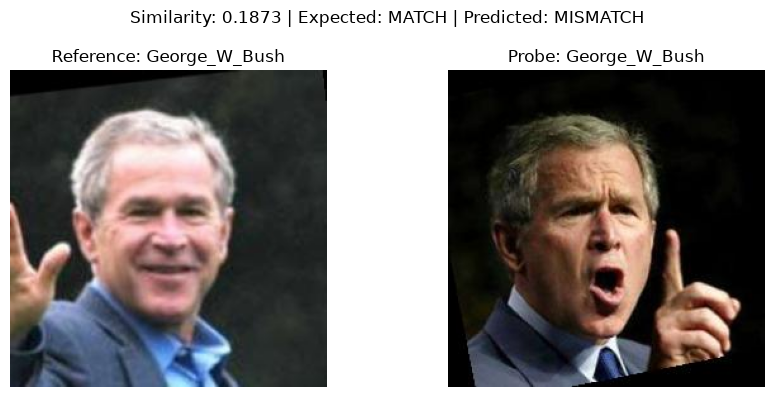

In [42]:
# Find incorrectly classified pairs
incorrect_pairs = results_df[
    results_df["status"] == "Incorrect"
]

print("Total incorrect predictions:", len(incorrect_pairs))

display(incorrect_pairs)

# Display incorrect pair images
if len(incorrect_pairs) > 0:

    for _, pair in incorrect_pairs.iterrows():

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))

        reference_img = cv2.cvtColor(
            cv2.imread(str(pairs_df.loc[
                (pairs_df["reference_path"] == pair["reference_identity"])
                if False else
                pairs_df["reference_path"].iloc[0]
            ])),
            cv2.COLOR_BGR2RGB
        ) if False else cv2.cvtColor(
            cv2.imread(str(next(
                p["reference_path"] for p in test_pairs
                if p["reference_identity"] == pair["reference_identity"]
                and p["probe_identity"] == pair["probe_identity"]
            ))),
            cv2.COLOR_BGR2RGB
        )

        probe_img = cv2.cvtColor(
            cv2.imread(str(next(
                p["probe_path"] for p in test_pairs
                if p["reference_identity"] == pair["reference_identity"]
                and p["probe_identity"] == pair["probe_identity"]
            ))),
            cv2.COLOR_BGR2RGB
        )

        axes[0].imshow(reference_img)
        axes[0].set_title("Reference: " + pair["reference_identity"])
        axes[0].axis("off")

        axes[1].imshow(probe_img)
        axes[1].set_title("Probe: " + pair["probe_identity"])
        axes[1].axis("off")

        plt.suptitle(
            f'Similarity: {pair["similarity"]:.4f} | '
            f'Expected: {pair["expected"]} | '
            f'Predicted: {pair["predicted"]}'
        )

        plt.tight_layout()
        plt.show()


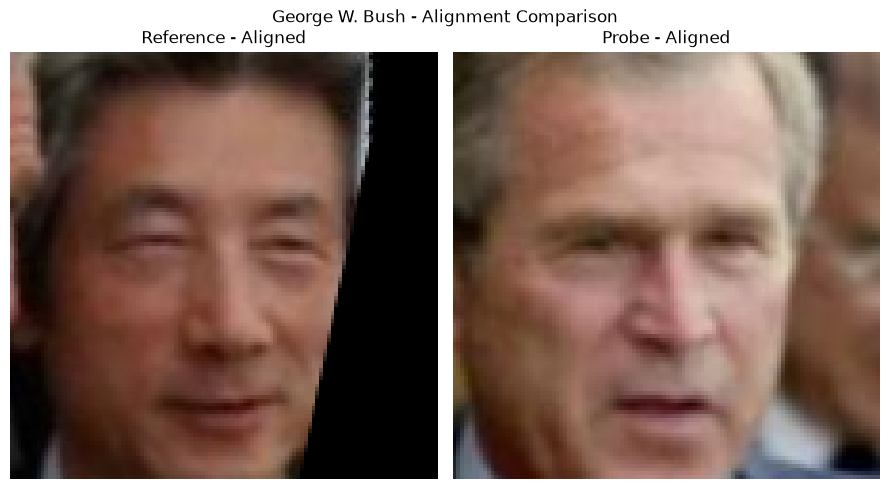

Original similarity: 0.1873


In [43]:
# Retrieve the incorrectly classified pair
incorrect_pair = pairs_df.iloc[32]

reference_path = incorrect_pair["reference_path"]
probe_path = incorrect_pair["probe_path"]

def get_aligned_face(image_path):

    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    result = landmarker.detect(mp_image)

    if not result.face_landmarks:
        raise ValueError("No face detected.")

    # Use the same largest-face policy as our embedding function
    landmarks = max(
        result.face_landmarks,
        key=lambda face: (
            max(p.x for p in face) - min(p.x for p in face)
        ) * (
            max(p.y for p in face) - min(p.y for p in face)
        )
    )

    height, width, _ = image.shape

    xs = [int(p.x * width) for p in landmarks]
    ys = [int(p.y * height) for p in landmarks]

    x_min = max(0, min(xs))
    y_min = max(0, min(ys))
    x_max = min(width - 1, max(xs))
    y_max = min(height - 1, max(ys))

    def get_point(index):
        return np.array([
            landmarks[index].x * width,
            landmarks[index].y * height
        ], dtype=np.float32)

    five_points = np.array([
        (get_point(33) + get_point(133)) / 2,
        (get_point(263) + get_point(362)) / 2,
        get_point(1),
        get_point(61),
        get_point(291)
    ], dtype=np.float32)

    face_data = np.array([
        x_min, y_min,
        x_max - x_min,
        y_max - y_min,
        *five_points.flatten(),
        1.0
    ], dtype=np.float32)

    return recognizer.alignCrop(
        image, face_data.reshape(1, -1)
    )

# Align both photographs
reference_aligned = get_aligned_face(reference_path)
probe_aligned = get_aligned_face(probe_path)

# Display aligned crops
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(cv2.cvtColor(
    reference_aligned, cv2.COLOR_BGR2RGB
))
axes[0].set_title("Reference - Aligned")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(
    probe_aligned, cv2.COLOR_BGR2RGB
))
axes[1].set_title("Probe - Aligned")
axes[1].axis("off")

plt.suptitle("George W. Bush - Alignment Comparison")
plt.tight_layout()
plt.show()

print("Original similarity:", round(
    float(np.dot(
        embedding_cache[reference_path],
        embedding_cache[probe_path]
    )), 4
))


Reference identity: George_W_Bush
Probe identity: George_W_Bush

Reference path:
D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\George_W_Bush\George_W_Bush_0276.jpg

Probe path:
D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\George_W_Bush\George_W_Bush_0293.jpg


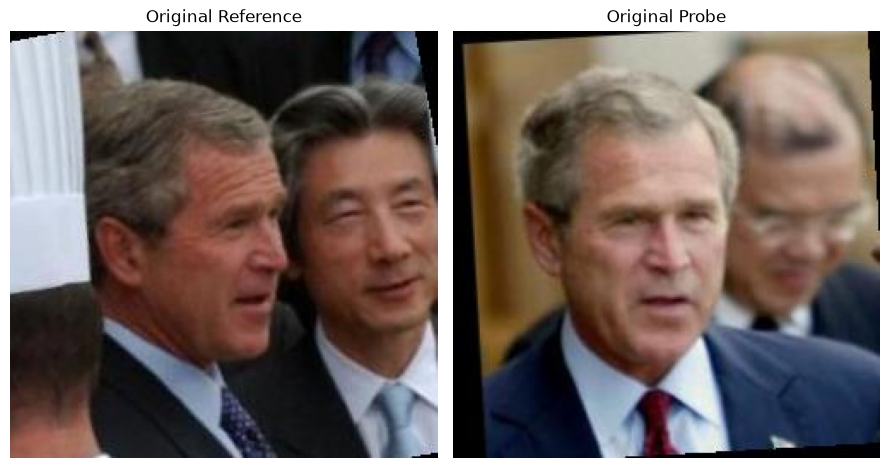

In [44]:
print("Reference identity:", incorrect_pair["reference_identity"])
print("Probe identity:", incorrect_pair["probe_identity"])

print("\nReference path:")
print(reference_path)

print("\nProbe path:")
print(probe_path)

# Display original images again
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

for ax, path, title in zip(
    axes,
    [reference_path, probe_path],
    ["Original Reference", "Original Probe"]
):
    img = cv2.cvtColor(
        cv2.imread(str(path)),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Total faces detected: 2


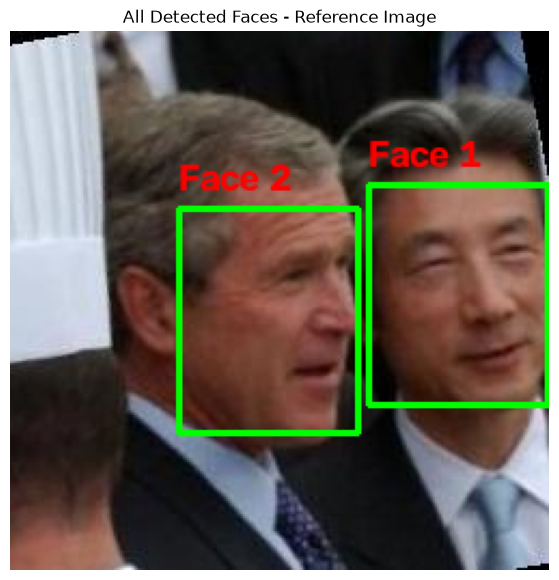

In [45]:
# Load the problematic reference image
image = cv2.imread(str(reference_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Detect all faces
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

height, width, _ = image.shape
display_image = image_rgb.copy()

print("Total faces detected:", len(result.face_landmarks))

for i, face in enumerate(result.face_landmarks):

    xs = [int(point.x * width) for point in face]
    ys = [int(point.y * height) for point in face]

    x_min = max(0, min(xs))
    y_min = max(0, min(ys))
    x_max = min(width - 1, max(xs))
    y_max = min(height - 1, max(ys))

    cv2.rectangle(
        display_image,
        (x_min, y_min),
        (x_max, y_max),
        (0, 255, 0),
        2
    )

    cv2.putText(
        display_image,
        f"Face {i + 1}",
        (x_min, max(20, y_min - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(10, 7))
plt.imshow(display_image)
plt.title("All Detected Faces - Reference Image")
plt.axis("off")
plt.show()


## automatic target-face selection using a registered reference photograph.

Selected reference: George_W_Bush_0001.jpg
Reference identity: George_W_Bush


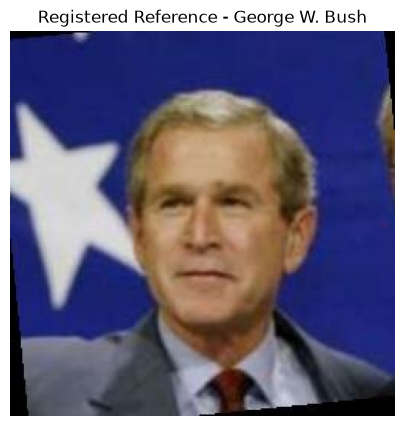

In [46]:

# Correct LFW identity folder path
identity_folder = (
    DATASET_PATH
    / "lfw-deepfunneled"
    / "George_W_Bush"
)

if not identity_folder.exists():
    raise FileNotFoundError(
        f"Identity folder not found: {identity_folder}"
    )

# Find an image containing exactly one detected face
clean_reference_path = None

for image_path in identity_folder.glob("*.jpg"):

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    detection_result = landmarker.detect(mp_image)

    if len(detection_result.face_landmarks) == 1:
        clean_reference_path = image_path
        break

if clean_reference_path is None:
    raise ValueError(
        "No single-face reference image found."
    )

print("Selected reference:", clean_reference_path.name)
print("Reference identity: George_W_Bush")

# Display image
reference_img = cv2.cvtColor(
    cv2.imread(str(clean_reference_path)),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(5, 5))
plt.imshow(reference_img)
plt.title("Registered Reference - George W. Bush")
plt.axis("off")
plt.show()


Generating registered id embeddings

In [47]:
# Generate embedding from the clean reference photograph
registered_embedding = extract_face_embedding(clean_reference_path)

print("Registered identity: George_W_Bush")
print("Embedding shape:", registered_embedding.shape)
print("Embedding dimensions:", len(registered_embedding))
print("Embedding norm:", round(
    float(np.linalg.norm(registered_embedding)), 4
))

print("\nReference embedding generated successfully!")


Registered identity: George_W_Bush
Embedding shape: (128,)
Embedding dimensions: 128
Embedding norm: 1.0

Reference embedding generated successfully!


Compare all detected faces against the registered identity

In [48]:
# Group photograph containing two people
probe_group_path = (
    DATASET_PATH
    / "lfw-deepfunneled"
    / "George_W_Bush"
    / "George_W_Bush_0276.jpg"
)

image = cv2.imread(str(probe_group_path))

if image is None:
    raise FileNotFoundError(probe_group_path)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Detect all faces
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

detection_result = landmarker.detect(mp_image)

print("Total faces detected:", len(detection_result.face_landmarks))

face_results = []

height, width, _ = image.shape

for i, landmarks in enumerate(detection_result.face_landmarks):

    # Calculate bounding box
    xs = [int(p.x * width) for p in landmarks]
    ys = [int(p.y * height) for p in landmarks]

    x_min = max(0, min(xs))
    y_min = max(0, min(ys))
    x_max = min(width - 1, max(xs))
    y_max = min(height - 1, max(ys))

    # Extract five facial reference points
    def get_point(index):
        return np.array([
            landmarks[index].x * width,
            landmarks[index].y * height
        ], dtype=np.float32)

    five_points = np.array([
        (get_point(33) + get_point(133)) / 2,
        (get_point(263) + get_point(362)) / 2,
        get_point(1),
        get_point(61),
        get_point(291)
    ], dtype=np.float32)

    # Prepare SFace alignment input
    face_data = np.array([
        x_min,
        y_min,
        x_max - x_min,
        y_max - y_min,
        *five_points.flatten(),
        1.0
    ], dtype=np.float32)

    # Align and extract embedding
    aligned_face = recognizer.alignCrop(
        image,
        face_data.reshape(1, -1)
    )

    face_embedding = recognizer.feature(
        aligned_face
    ).flatten()

    # Normalize embedding
    norm = np.linalg.norm(face_embedding)

    if norm == 0:
        raise ValueError(f"Invalid embedding for Face {i+1}")

    face_embedding = face_embedding / norm

    # Compare with registered identity
    similarity = float(
        np.dot(registered_embedding, face_embedding)
    )

    face_results.append({
        "face_number": i + 1,
        "embedding": face_embedding,
        "similarity": similarity,
        "box": (x_min, y_min, x_max, y_max)
    })

# Display similarity scores
for face in face_results:
    print(
        f'Face {face["face_number"]}: '
        f'Similarity = {face["similarity"]:.4f}'
    )

# Identify highest similarity
if not face_results:
    raise ValueError("No faces detected in the probe image.")

best_face = max(
    face_results,
    key=lambda item: item["similarity"]
)

THRESHOLD = 0.3822

if best_face["similarity"] >= THRESHOLD:
    print("\nRegistered identity found!")
    print("Matching face:", best_face["face_number"])
else:
    print("\nRegistered identity not confidently found.")


Total faces detected: 2
Face 1: Similarity = 0.1265
Face 2: Similarity = 0.7106

Registered identity found!
Matching face: 2


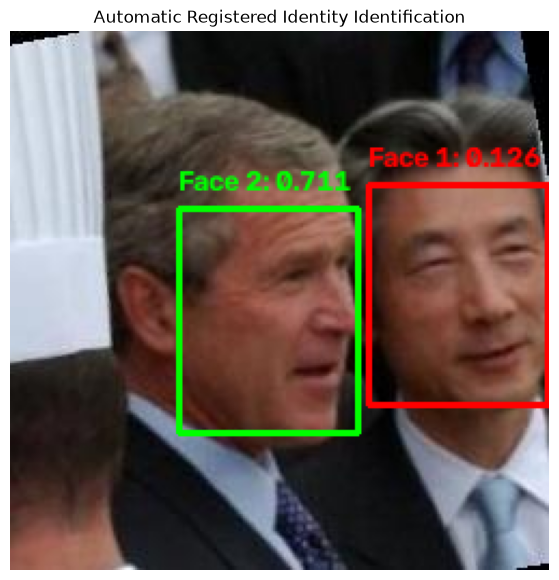

In [49]:
display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()

for face in face_results:

    x_min, y_min, x_max, y_max = face["box"]

    is_match = face["face_number"] == best_face["face_number"]

    color = (0, 255, 0) if (
        is_match and best_face["similarity"] >= THRESHOLD
    ) else (255, 0, 0)

    label = (
        f'Face {face["face_number"]}: '
        f'{face["similarity"]:.3f}'
    )

    cv2.rectangle(
        display_image,
        (x_min, y_min),
        (x_max, y_max),
        color,
        2
    )

    cv2.putText(
        display_image,
        label,
        (x_min, max(20, y_min - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        color,
        2
    )

plt.figure(figsize=(9, 7))
plt.imshow(display_image)
plt.title("Automatic Registered Identity Identification")
plt.axis("off")
plt.show()


TESTING THIS APROACH ON OTHER GROUP IMAGE

Selected group image: George_W_Bush_0018.jpg
Faces detected: 2


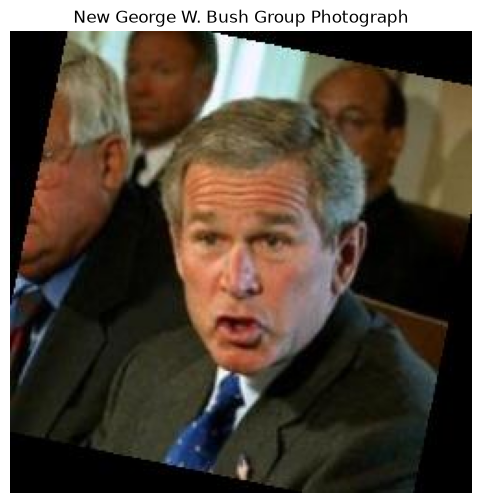

In [50]:
# Search for another group photograph of George W. Bush
group_image_path = None
group_face_count = 0

for image_path in identity_folder.glob("*.jpg"):

    # Skip the registered reference image
    if image_path == clean_reference_path:
        continue

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    detection = landmarker.detect(mp_image)
    detected_count = len(detection.face_landmarks)

    if detected_count >= 2:
        group_image_path = image_path
        group_face_count = detected_count
        break

if group_image_path is None:
    raise ValueError(
        "No additional group photograph found."
    )

print("Selected group image:", group_image_path.name)
print("Faces detected:", group_face_count)

# Display selected image
group_image = cv2.imread(str(group_image_path))
group_image_rgb = cv2.cvtColor(
    group_image, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 6))
plt.imshow(group_image_rgb)
plt.title("New George W. Bush Group Photograph")
plt.axis("off")
plt.show()


In [51]:
# Load new group photograph
image = cv2.imread(str(group_image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

detection_result = landmarker.detect(mp_image)

height, width, _ = image.shape
face_results = []

for i, landmarks in enumerate(detection_result.face_landmarks):

    # Calculate bounding box
    xs = [int(p.x * width) for p in landmarks]
    ys = [int(p.y * height) for p in landmarks]

    x_min = max(0, min(xs))
    y_min = max(0, min(ys))
    x_max = min(width - 1, max(xs))
    y_max = min(height - 1, max(ys))

    # Five facial reference points
    def get_point(index):
        return np.array([
            landmarks[index].x * width,
            landmarks[index].y * height
        ], dtype=np.float32)

    five_points = np.array([
        (get_point(33) + get_point(133)) / 2,
        (get_point(263) + get_point(362)) / 2,
        get_point(1),
        get_point(61),
        get_point(291)
    ], dtype=np.float32)

    # Prepare SFace input
    face_data = np.array([
        x_min, y_min,
        x_max - x_min,
        y_max - y_min,
        *five_points.flatten(),
        1.0
    ], dtype=np.float32)

    # Align and extract embedding
    aligned_face = recognizer.alignCrop(
        image,
        face_data.reshape(1, -1)
    )

    embedding = recognizer.feature(
        aligned_face
    ).flatten()

    norm = np.linalg.norm(embedding)

    if norm == 0:
        continue

    embedding = embedding / norm

    # Compare against registered candidate
    similarity = float(
        np.dot(registered_embedding, embedding)
    )

    face_results.append({
        "face_number": i + 1,
        "similarity": similarity,
        "box": (x_min, y_min, x_max, y_max)
    })

# Display similarity scores
for face in face_results:
    print(
        f'Face {face["face_number"]}: '
        f'Similarity = {face["similarity"]:.4f}'
    )

# Identify best match
if not face_results:
    raise ValueError("No usable face embeddings generated.")

best_face = max(
    face_results,
    key=lambda item: item["similarity"]
)

THRESHOLD = 0.3822

if best_face["similarity"] >= THRESHOLD:
    print("\nRegistered candidate identified!")
    print("Matching face:", best_face["face_number"])
else:
    print("\nRegistered candidate not found.")


Face 1: Similarity = 0.6937
Face 2: Similarity = 0.0364

Registered candidate identified!
Matching face: 1


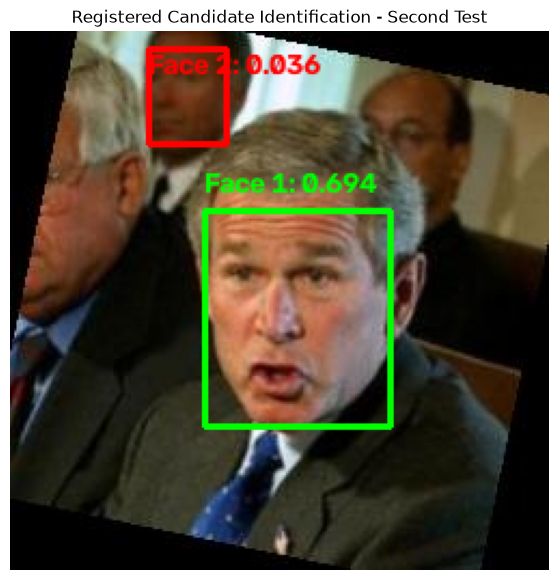

In [52]:
display_image = cv2.cvtColor(
    image, cv2.COLOR_BGR2RGB
).copy()

for face in face_results:

    x_min, y_min, x_max, y_max = face["box"]

    is_match = (
        face["face_number"] == best_face["face_number"]
        and best_face["similarity"] >= THRESHOLD
    )

    color = (0, 255, 0) if is_match else (255, 0, 0)

    label = (
        f'Face {face["face_number"]}: '
        f'{face["similarity"]:.3f}'
    )

    cv2.rectangle(
        display_image,
        (x_min, y_min),
        (x_max, y_max),
        color,
        2
    )

    cv2.putText(
        display_image,
        label,
        (x_min, max(20, y_min - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        color,
        2
    )

plt.figure(figsize=(9, 7))
plt.imshow(display_image)
plt.title("Registered Candidate Identification - Second Test")
plt.axis("off")
plt.show()


TEST WHEN REGISTERED CANDIDATE IS ABSENT

Registered identity: George_W_Bush
Selected probe identity: Dave_McGinnis
Probe image: Dave_McGinnis_0001.jpg


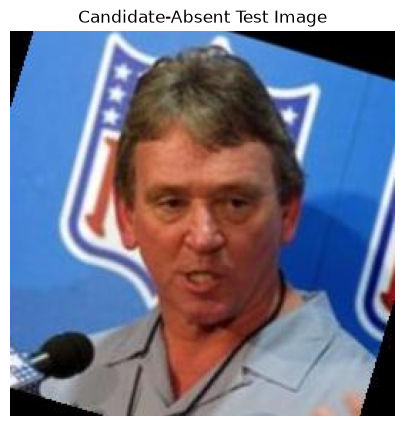

In [53]:
# SELECT NAD DISPLAY ANOTHER PERSONS IMAGE
# Find other identity folders
lfw_root = DATASET_PATH / "lfw-deepfunneled"

other_identity_folders = [
    folder for folder in lfw_root.iterdir()
    if folder.is_dir()
    and folder.name != "George_W_Bush"
    and list(folder.glob("*.jpg"))
]

# Select a different identity
random.seed(100)

absent_identity_folder = random.choice(other_identity_folders)

absent_image_path = random.choice(
    list(absent_identity_folder.glob("*.jpg"))
)

print("Registered identity: George_W_Bush")
print("Selected probe identity:", absent_identity_folder.name)
print("Probe image:", absent_image_path.name)

# Display image
absent_image = cv2.imread(str(absent_image_path))

if absent_image is None:
    raise ValueError("Unable to load probe image.")

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(absent_image, cv2.COLOR_BGR2RGB))
plt.title("Candidate-Absent Test Image")
plt.axis("off")
plt.show()


Total faces detected: 1


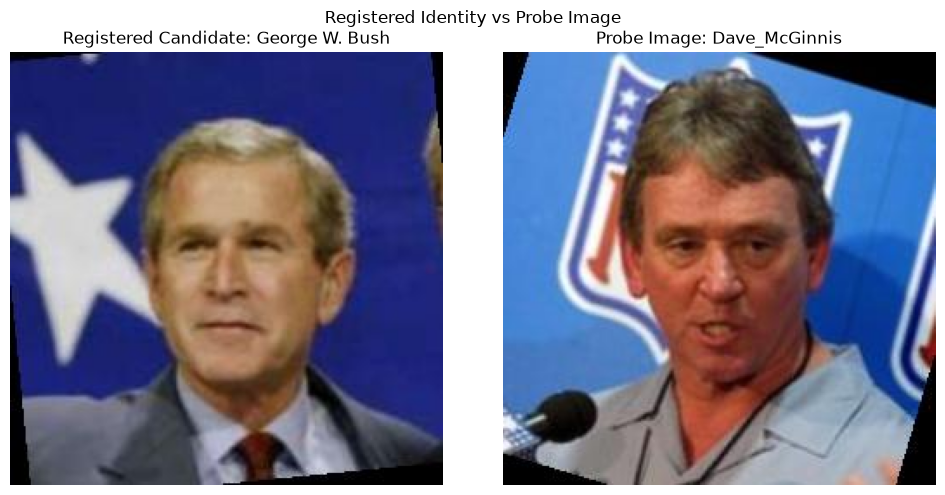

Face 1: Similarity = 0.2012

REGISTERED CANDIDATE NOT FOUND


In [54]:
# Convert image and detect faces
absent_rgb = cv2.cvtColor(absent_image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=absent_rgb
)

detection = landmarker.detect(mp_image)

height, width, _ = absent_image.shape

absent_face_results = []

print("Total faces detected:", len(detection.face_landmarks))


# Display registered reference and probe image
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Registered candidate
registered_img = cv2.cvtColor(
    cv2.imread(str(clean_reference_path)),
    cv2.COLOR_BGR2RGB
)

axes[0].imshow(registered_img)
axes[0].set_title("Registered Candidate: George W. Bush")
axes[0].axis("off")

# Candidate-absent probe
axes[1].imshow(absent_rgb)
axes[1].set_title(
    f"Probe Image: {absent_identity_folder.name}"
)
axes[1].axis("off")

plt.suptitle("Registered Identity vs Probe Image")
plt.tight_layout()
plt.show()


for i, landmarks in enumerate(detection.face_landmarks):

    # Calculate bounding box
    xs = [int(p.x * width) for p in landmarks]
    ys = [int(p.y * height) for p in landmarks]

    x_min = max(0, min(xs))
    y_min = max(0, min(ys))
    x_max = min(width - 1, max(xs))
    y_max = min(height - 1, max(ys))

    # Extract five facial reference points
    def get_point(index):
        return np.array([
            landmarks[index].x * width,
            landmarks[index].y * height
        ], dtype=np.float32)

    five_points = np.array([
        (get_point(33) + get_point(133)) / 2,
        (get_point(263) + get_point(362)) / 2,
        get_point(1),
        get_point(61),
        get_point(291)
    ], dtype=np.float32)

    # Prepare SFace input
    face_data = np.array([
        x_min, y_min,
        x_max - x_min,
        y_max - y_min,
        *five_points.flatten(),
        1.0
    ], dtype=np.float32)

    # Align and extract embedding
    aligned_face = recognizer.alignCrop(
        absent_image,
        face_data.reshape(1, -1)
    )

    embedding = recognizer.feature(aligned_face).flatten()

    norm = np.linalg.norm(embedding)

    if norm == 0:
        continue

    embedding = embedding / norm

    # Compare with registered George W. Bush embedding
    similarity = float(
        np.dot(registered_embedding, embedding)
    )

    absent_face_results.append({
        "face_number": i + 1,
        "similarity": similarity,
        "box": (x_min, y_min, x_max, y_max)
    })

    print(
        f"Face {i+1}: Similarity = {similarity:.4f}"
    )

# Determine whether registered candidate is present
THRESHOLD = 0.3822

matching_faces = [
    face for face in absent_face_results
    if face["similarity"] >= THRESHOLD
]

if not absent_face_results:
    print("\nNo usable face detected. Candidate presence cannot be verified.")

elif matching_faces:
    print("\nRegistered candidate potentially present.")
    print("Matching faces:", len(matching_faces))

else:
    print("\nREGISTERED CANDIDATE NOT FOUND")


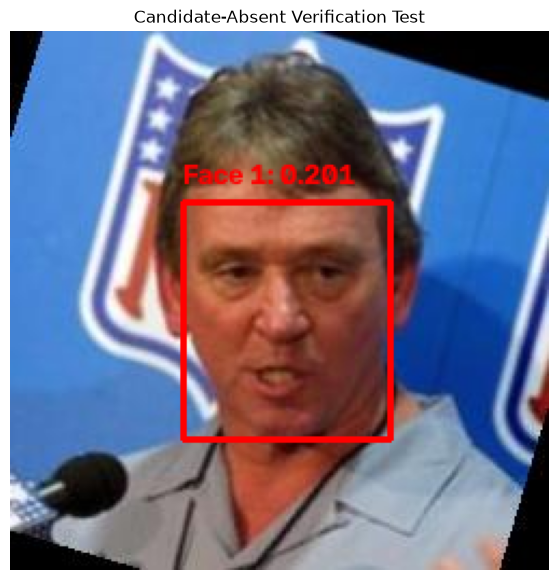

In [55]:
display_image = cv2.cvtColor(
    absent_image, cv2.COLOR_BGR2RGB
).copy()

for face in absent_face_results:

    x_min, y_min, x_max, y_max = face["box"]

    is_match = face["similarity"] >= THRESHOLD

    color = (0, 255, 0) if is_match else (255, 0, 0)

    label = (
        f'Face {face["face_number"]}: '
        f'{face["similarity"]:.3f}'
    )

    cv2.rectangle(
        display_image,
        (x_min, y_min),
        (x_max, y_max),
        color,
        2
    )

    cv2.putText(
        display_image,
        label,
        (x_min, max(20, y_min - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        color,
        2
    )

plt.figure(figsize=(9, 7))
plt.imshow(display_image)
plt.title("Candidate-Absent Verification Test")
plt.axis("off")
plt.show()


## Create the reusable face extraction function
This function will:
1. Accept an image.
2. Detect all faces using MediaPipe.
3. Extract five facial reference points for each face.
4. Align each face using SFace.
5. Generate a normalized 128-dimensional embedding.
6. Return the embeddings and bounding boxes.

In [56]:
def extract_all_face_embeddings(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unable to load image: {image_path}")

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Detect all faces using MediaPipe
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    detection = landmarker.detect(mp_image)

    height, width, _ = image.shape
    face_results = []

    # Process every detected face
    for i, landmarks in enumerate(detection.face_landmarks):

        # Calculate bounding box
        xs = [int(p.x * width) for p in landmarks]
        ys = [int(p.y * height) for p in landmarks]

        x_min = max(0, min(xs))
        y_min = max(0, min(ys))
        x_max = min(width - 1, max(xs))
        y_max = min(height - 1, max(ys))

        # Extract five facial reference points
        def get_point(index):
            return np.array([
                landmarks[index].x * width,
                landmarks[index].y * height
            ], dtype=np.float32)

        five_points = np.array([
            (get_point(33) + get_point(133)) / 2,
            (get_point(263) + get_point(362)) / 2,
            get_point(1),
            get_point(61),
            get_point(291)
        ], dtype=np.float32)

        # Prepare SFace alignment input
        face_data = np.array([
            x_min,
            y_min,
            x_max - x_min,
            y_max - y_min,
            *five_points.flatten(),
            1.0
        ], dtype=np.float32)

        # Align face
        aligned_face = recognizer.alignCrop(
            image,
            face_data.reshape(1, -1)
        )

        # Extract embedding
        embedding = recognizer.feature(
            aligned_face
        ).flatten()

        # Normalize embedding
        norm = np.linalg.norm(embedding)

        if norm == 0:
            continue

        embedding = embedding / norm

        face_results.append({
            "face_number": i + 1,
            "embedding": embedding,
            "box": (x_min, y_min, x_max, y_max),
            "aligned_face": aligned_face
        })

    return image, face_results


print("Face extraction function defined successfully!")


Face extraction function defined successfully!


In [57]:
test_image_path = group_image_path

test_image, detected_faces = extract_all_face_embeddings(
    test_image_path
)

print("Total faces detected:", len(detected_faces))

for face in detected_faces:
    print(
        f'Face {face["face_number"]}: '
        f'Embedding shape = {face["embedding"].shape}'
    )


Total faces detected: 2
Face 1: Embedding shape = (128,)
Face 2: Embedding shape = (128,)


In [58]:
def register_candidate(reference_image_path, candidate_id):

    # Extract faces from reference image
    image, face_results = extract_all_face_embeddings(
        reference_image_path
    )

    # Reference image must contain exactly one face
    if len(face_results) == 0:
        raise ValueError("No face detected in reference image.")

    if len(face_results) > 1:
        raise ValueError(
            "Multiple faces detected in reference image. "
            "Please provide a clear single-face reference."
        )

    # Store the candidate's embedding
    registered_data = {
        "candidate_id": candidate_id,
        "embedding": face_results[0]["embedding"],
        "reference_image": str(reference_image_path)
    }

    return registered_data


print("Candidate registration function defined successfully!")


Candidate registration function defined successfully!


In [59]:
registered_candidate = register_candidate(
    clean_reference_path,
    "George_W_Bush"
)

registered_embedding = registered_candidate["embedding"]

print("Candidate registered successfully!")
print("Candidate ID:", registered_candidate["candidate_id"])
print("Embedding shape:", registered_embedding.shape)
print("Embedding norm:", round(
    float(np.linalg.norm(registered_embedding)), 4
))


Candidate registered successfully!
Candidate ID: George_W_Bush
Embedding shape: (128,)
Embedding norm: 1.0


Automatic identity verification

In [60]:
def verify_registered_identity(
    registered_candidate,
    probe_image_path,
    threshold=0.3822
):

    # Extract all faces from the probe image
    image, face_results = extract_all_face_embeddings(
        probe_image_path
    )

    reference_embedding = registered_candidate["embedding"]

    verification_results = []

    # Compare every detected face
    for face in face_results:

        probe_embedding = face["embedding"]

        similarity = float(
            np.dot(reference_embedding, probe_embedding)
        )

        verification_results.append({
            "face_number": face["face_number"],
            "similarity": similarity,
            "predicted": (
                "MATCH" if similarity >= threshold
                else "MISMATCH"
            ),
            "box": face["box"]
        })

    # Identify the highest-scoring face
    matching_faces = [
        face for face in verification_results
        if face["similarity"] >= threshold
    ]

    best_match = (
        max(matching_faces, key=lambda x: x["similarity"])
        if matching_faces else None
    )

    # 1. Face monitoring status
    total_faces = len(face_results)

    if total_faces == 0:
        monitoring_status = "NO_FACE_DETECTED"
    elif total_faces == 1:
        monitoring_status = "SINGLE_FACE_DETECTED"
    else:
        monitoring_status = "MULTIPLE_FACES_DETECTED"

    # 2. Identity verification status
    if total_faces == 0:
        identity_status = "NOT_VERIFIED"
    elif not matching_faces:
        identity_status = "CANDIDATE_NOT_FOUND"
    elif len(matching_faces) == 1:
        identity_status = "CANDIDATE_IDENTIFIED"
    else:
        identity_status = "MULTIPLE_MATCHES_FOUND"

    return {
        "candidate_id": registered_candidate["candidate_id"],
        "monitoring_status": monitoring_status,
        "identity_status": identity_status,
        "total_faces": total_faces,
        "matching_faces_count": len(matching_faces),
        "best_match": best_match,
        "face_results": verification_results,
        "image": image
    }

print("Identity verification function defined successfully!")


Identity verification function defined successfully!


In [61]:
verification_output = verify_registered_identity(
    registered_candidate,
    group_image_path
)

print("Registered candidate:",
      verification_output["candidate_id"])

print("Total faces detected:",
      verification_output["total_faces"])

print("Face monitoring status:",
      verification_output["monitoring_status"])

print("Identity verification status:",
      verification_output["identity_status"])

print("Matching faces count:",
      verification_output["matching_faces_count"])

print("\nIndividual face comparisons:")

for face in verification_output["face_results"]:
    print(
        f'Face {face["face_number"]}: '
        f'Similarity = {face["similarity"]:.4f} | '
        f'Prediction = {face["predicted"]}'
    )

if verification_output["best_match"]:
    print("\nMatching face:",
          verification_output["best_match"]["face_number"])


Registered candidate: George_W_Bush
Total faces detected: 2
Face monitoring status: MULTIPLE_FACES_DETECTED
Identity verification status: CANDIDATE_IDENTIFIED
Matching faces count: 1

Individual face comparisons:
Face 1: Similarity = 0.6937 | Prediction = MATCH
Face 2: Similarity = 0.0364 | Prediction = MISMATCH

Matching face: 1


Visualization function defined successfully!


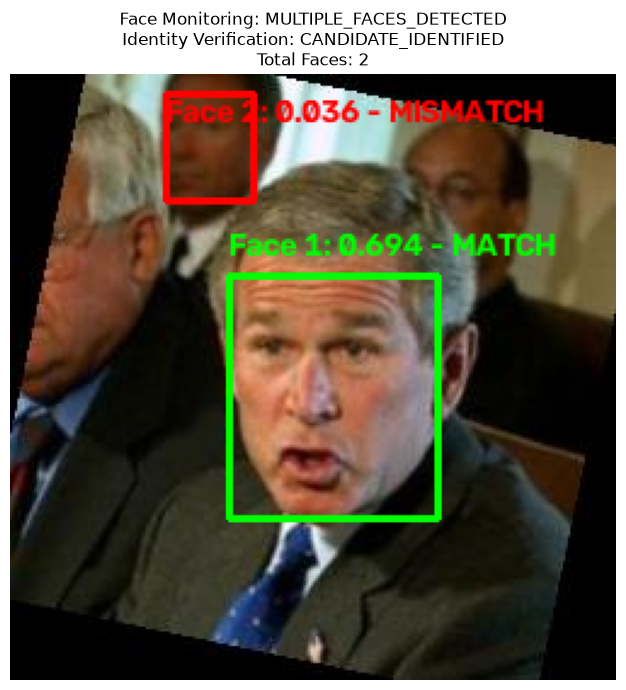

In [62]:
def visualize_verification(verification_output):

    image = verification_output["image"].copy()

    for face in verification_output["face_results"]:

        x_min, y_min, x_max, y_max = face["box"]

        is_match = face["predicted"] == "MATCH"

        # Green for candidate match, red for non-match
        color = (0, 255, 0) if is_match else (0, 0, 255)

        label = (
            f'Face {face["face_number"]}: '
            f'{face["similarity"]:.3f} - '
            f'{face["predicted"]}'
        )

        cv2.rectangle(
            image,
            (x_min, y_min),
            (x_max, y_max),
            color,
            2
        )

        cv2.putText(
            image,
            label,
            (x_min, max(20, y_min - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            color,
            2
        )

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    monitoring_status = verification_output["monitoring_status"]
    identity_status = verification_output["identity_status"]
    total_faces = verification_output["total_faces"]

    plt.figure(figsize=(10, 7))
    plt.imshow(image_rgb)

    plt.title(
        f"Face Monitoring: {monitoring_status}\n"
        f"Identity Verification: {identity_status}\n"
        f"Total Faces: {total_faces}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


print("Visualization function defined successfully!")

visualize_verification(verification_output)

